# INSY 674 · Model Comparison, Feature Selection and Shortlist

## Summary

This notebook compares **nine models from seven families** with 5-fold CV (mean ± SD of average precision, AP) in a leak-free pipeline. It analyzes their key variables and error types, runs two further iterations of feature engineering and selection, and shortlists the models for fine-tuning. Only the training set is used. Random ranking gives AP 0.156.

**Main findings**

1. **Iteration 1 (raw inputs, default settings).**
   - **Random forest (0.740 ± 0.022) and LightGBM (0.740 ± 0.018) lead,** followed by the MLP (0.725), SVM (0.717), XGBoost (0.716) and KNN (0.707).
   - Logistic regression (0.684), naive Bayes (0.535) and a single decision tree (0.387) trail.
   - The tree ensembles and KNN reach train AP of 0.97–1.0, so they memorize the training data at default settings.
2. **Key variables.** For **every** algorithm, `PageValues` is by far the most important input: shuffling it costs 0.22–0.54 AP. `Month`, `ExitRates` and `BounceRates` follow. `Region`, `OperatingSystems`, `Browser` and `Informational_Duration` are useless or harmful for most models.
3. **Errors are driven by `PageValues` pointing the wrong way.**
   - **Missed buyers:** 65–70 % of them have `PageValues = 0`, against 20 % of all buyers.
   - **False alarms:** they browse a lot (≈ 40 product pages against 16 for typical non-buyers) and have a high `PageValues`.
   - **Shared errors:** 371 sessions are misclassified by all nine models. Telling these apart needs data the set does not contain, such as cart and checkout events, prices and customer history.
4. **`PageValues` leakage check.**
   - It is **not a copy of the outcome**: 19.5 % of buyers have `PageValues = 0`, and 11.6 % of non-buyers have a positive value.
   - The models depend on it heavily, however. Without it, AP falls to 0.31–0.37, keeping only about a third of the gain over random.
   - The **ranking of the models hardly changes** without it (RF and LightGBM stay on top), so the shortlist does not depend on this decision.
5. **Feature engineering did not help, but feature selection did.**
   - Adding the 12 engineered features changed AP by between −0.019 and +0.003 for the stronger models (−0.09 for naive Bayes), mostly within noise.
   - Per-model selection, which drops inputs with no importance, raised AP for most models: KNN +0.017, MLP +0.015, SVM +0.012, XGBoost +0.008, RF +0.005. **Naive Bayes rose by +0.124**, because dropping the six correlated count/duration inputs removes its double counting.
6. **Shortlist (5 models): random forest, XGBoost, KNN, LightGBM, neural network (MLP).**
   - All are within one fold SD of the best model (RF, 0.745 ± 0.024). They were added greedily by **least error overlap** with the models already chosen.
   - SVM also qualified on score, but its errors overlap most with the others, so it was dropped. Logistic regression, naive Bayes and the decision tree are more than 0.05 AP behind.
   - The selected feature configuration of each shortlisted model is saved to `model_comparison_results/shortlist.json` and used in `fine_tuning_models.ipynb`.

## 0 · Data, Pipeline and Protocol

### Inputs and train/test separation

- `train_raw.csv` and `test_raw.csv` come from `Online_Purchase_Intention_EDA.ipynb`. That notebook removed exact duplicate sessions **before** splitting and made a stratified 80/20 split with seed 42.
- **This notebook reads only the training file.** The test set is kept for the single final evaluation at the end of `fine_tuning_models.ipynb`.

### Cleaning, feature engineering and scaling, all inside one leak-free pipeline

| Step | What is done | Why | Fitted on |
|---|---|---|---|
| Cleaning | There are no missing values, so nothing is imputed. Codes such as `Browser` or `TrafficType` are treated as **nominal labels**, and `Weekend` becomes a category. | A value like `TrafficType = 10` is a label, not an amount. | Nothing is learned |
| Feature engineering | The EDA notebook's 12 session-level features (totals, average time per page, shares, zero-activity flags). They are optional and tested in iteration 2. | They describe browsing depth and focus more directly. | Nothing is learned (row-wise formulas) |
| Rare categories | Levels seen in fewer than 1 % of training sessions are merged into one "infrequent" level. This is optional and tested in iteration 3. | It avoids noisy estimates for rare browsers and traffic types. | Training part of each fold |
| Encoding | One-hot encoding. Unknown levels at prediction time are ignored or mapped to "infrequent". | Most model families need numeric inputs. | Training part of each fold |
| Scaling (distance, linear, kernel and neural models) | `log1p` on counts, durations and `PageValues`, followed by `StandardScaler`. | These columns have long right tails and many zeros, and these models are sensitive to scale. | Training part of each fold |
| Binning (naive Bayes) | 10 quantile bins per continuous column. | The inputs are far from normal; bins need no distribution assumption. | Training part of each fold |
| Tree models | No scaling. | Splits depend only on the order of values. | — |

Every learned step sits inside a scikit-learn `Pipeline`, so it is refitted on the training part of each fold and never sees the validation rows.

### Evaluation

- 5-fold stratified CV with the team's folds (`StratifiedKFold(5, shuffle=True, random_state=42)`), reported as **mean ± SD over the 5 folds**.
- Main metric: **average precision (AP)**, because only 15.6 % of sessions buy. Random ranking gives AP ≈ 0.156.
- ROC-AUC and train AP (to show overfitting) are reported as well. Error analysis uses the threshold that maximizes F1 on the out-of-fold predictions.

### `PageValues` policy (group decision)

The main analysis **includes** `PageValues`. Its leakage risk is examined in §2, and every model is also cross-validated **without** it.

In [1]:
import json
import os
import time
import warnings
from collections import defaultdict
from pathlib import Path

os.environ['PYTHONWARNINGS'] = 'ignore:Bins whose width are too small:UserWarning'

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import xgboost as xgb
from IPython.display import display
from joblib import Parallel, delayed
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, f1_score, precision_recall_curve, roc_auc_score
from sklearn.model_selection import StratifiedKFold
from sklearn.naive_bayes import BernoulliNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, KBinsDiscretizer, OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from threadpoolctl import threadpool_limits

warnings.filterwarnings('ignore', message='Bins whose width are too small')
pd.set_option('display.float_format', lambda v: f'{v:.4f}')
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 220)

SEED = 42
N_JOBS = os.cpu_count() or 1
OUT = Path('model_comparison_results')
OUT.mkdir(exist_ok=True)
TARGET = 'Revenue'

COUNTS = ['Administrative', 'Informational', 'ProductRelated']
DURATIONS = [c + '_Duration' for c in COUNTS]
RAW_NUM = ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated',
           'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay']
CATS = ['Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend']
FEATURES = RAW_NUM + CATS
EDA12 = ['TotalPages', 'TotalDuration', 'AvgTimePerPage', 'AvgProductTime', 'AvgAdminTime', 'AvgInfoTime',
         'ProductPageShare', 'ProductTimeShare', 'NoTrackedPages', 'ZeroDurationSession', 'AnyInformational',
         'AnyAdministrative']
LOG_SET = set(COUNTS + DURATIONS + ['PageValues', 'TotalPages', 'TotalDuration', 'AvgTimePerPage', 'AvgProductTime',
                                    'AvgAdminTime', 'AvgInfoTime'])
FLAG_SET = {'NoTrackedPages', 'ZeroDurationSession', 'AnyInformational', 'AnyAdministrative'}

train = pd.read_csv('train_raw.csv')
X, y = train[FEATURES], train[TARGET].astype(int).to_numpy()
FOLDS = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(X, y))

checks = {'rows': len(train), 'purchase rate': round(y.mean(), 4), 'missing values': int(X.isna().sum().sum()),
          'duplicate rows (all predictors)': int(X.duplicated().sum()), 'negative numeric values': int((X[RAW_NUM] < 0).sum().sum())}
display(pd.Series(checks, name='training data checks'))
print(f'scikit-learn {sklearn.__version__} | xgboost {xgb.__version__} | lightgbm {lgb.__version__} | workers {N_JOBS}')

rows                              9764.0000
purchase rate                        0.1563
missing values                       0.0000
duplicate rows (all predictors)      0.0000
negative numeric values              0.0000
Name: training data checks, dtype: float64

scikit-learn 1.9.1 | xgboost 3.4.1 | lightgbm 4.7.0 | workers 10


**Data checks.**
- **No missing values and no negative values,** so imputation and outlier removal are not needed. Long tails are valid sessions, which is why they are compressed (log, bins) rather than removed.
- **No duplicate predictor rows remain,** because the EDA notebook removed exact duplicates before the split.

In [2]:
def safe_div(a, b):
    return np.where(b > 0, a / np.where(b > 0, b, 1), 0.0)


class SessionFeatures(BaseEstimator, TransformerMixin):
    # Stateless: row-wise formulas only, so it cannot leak across folds.
    def __init__(self, engineered=False, drop=(), include_pv=True):
        self.engineered = engineered
        self.drop = drop
        self.include_pv = include_pv

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        z = X[FEATURES].copy()
        z[CATS] = z[CATS].astype(str).astype(object)
        if self.engineered:
            pages, dur = z[COUNTS].sum(axis=1), z[DURATIONS].sum(axis=1)
            z['TotalPages'], z['TotalDuration'] = pages, dur
            z['AvgTimePerPage'] = safe_div(dur, pages)
            z['AvgProductTime'] = safe_div(z['ProductRelated_Duration'], z['ProductRelated'])
            z['AvgAdminTime'] = safe_div(z['Administrative_Duration'], z['Administrative'])
            z['AvgInfoTime'] = safe_div(z['Informational_Duration'], z['Informational'])
            z['ProductPageShare'] = safe_div(z['ProductRelated'], pages)
            z['ProductTimeShare'] = safe_div(z['ProductRelated_Duration'], dur)
            z['NoTrackedPages'] = (pages == 0).astype(int)
            z['ZeroDurationSession'] = ((pages > 0) & (dur == 0)).astype(int)
            z['AnyInformational'] = (z['Informational'] > 0).astype(int)
            z['AnyAdministrative'] = (z['Administrative'] > 0).astype(int)
        removed = list(self.drop) + ([] if self.include_pv else ['PageValues'])
        return z.drop(columns=[c for c in removed if c in z.columns])


# Column selectors (called on the transformed frame inside each fold)
def log_cols(df): return [c for c in df.columns if c in LOG_SET]
def lin_cols(df): return [c for c in df.select_dtypes('number').columns if c not in LOG_SET]
def num_cols(df): return list(df.select_dtypes('number').columns)
def cont_cols(df): return [c for c in df.select_dtypes('number').columns if c not in FLAG_SET]
def flag_cols(df): return [c for c in df.select_dtypes('number').columns if c in FLAG_SET]
def cat_cols(df): return list(df.select_dtypes(exclude='number').columns)


ESTIMATORS = {
    'Logistic regression': lambda: LogisticRegression(max_iter=3000),
    'Naive Bayes': lambda: BernoulliNB(),
    'KNN': lambda: KNeighborsClassifier(n_neighbors=25, weights='distance', algorithm='brute', n_jobs=1),
    'SVM (RBF)': lambda: SVC(probability=True, random_state=SEED),
    'Neural network (MLP)': lambda: MLPClassifier(hidden_layer_sizes=(64, 32), early_stopping=True, max_iter=500,
                                                  random_state=SEED),
    'Decision tree': lambda: DecisionTreeClassifier(random_state=SEED),
    'Random forest': lambda: RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=1),
    'XGBoost': lambda: xgb.XGBClassifier(tree_method='hist', eval_metric='logloss', random_state=SEED, n_jobs=1),
    'LightGBM': lambda: lgb.LGBMClassifier(random_state=SEED, n_jobs=1, verbose=-1),
}
FAMILY = {'Logistic regression': 'linear', 'Naive Bayes': 'probabilistic', 'KNN': 'instance-based',
          'SVM (RBF)': 'kernel', 'Neural network (MLP)': 'neural network', 'Decision tree': 'single tree',
          'Random forest': 'bagged trees', 'XGBoost': 'boosted trees', 'LightGBM': 'boosted trees'}
SCALED = {'Logistic regression', 'KNN', 'SVM (RBF)', 'Neural network (MLP)'}
MODELS = list(ESTIMATORS)


def make_model(name, engineered=False, drop=(), rare=False, include_pv=True):
    enc = OneHotEncoder(handle_unknown='infrequent_if_exist' if rare else 'ignore',
                        min_frequency=0.01 if rare else None, sparse_output=False)
    if name in SCALED:
        prep = ColumnTransformer([('log', Pipeline([('log1p', FunctionTransformer(np.log1p)), ('scale', StandardScaler())]),
                                   log_cols),
                                  ('linear', StandardScaler(), lin_cols), ('cat', enc, cat_cols)])
    elif name == 'Naive Bayes':
        prep = ColumnTransformer([('bins', KBinsDiscretizer(n_bins=10, encode='onehot-dense', strategy='quantile',
                                                            quantile_method='averaged_inverted_cdf'), cont_cols),
                                  ('flags', 'passthrough', flag_cols), ('cat', enc, cat_cols)])
    else:
        prep = ColumnTransformer([('num', 'passthrough', num_cols), ('cat', enc, cat_cols)])
    return Pipeline([('features', SessionFeatures(engineered, tuple(drop), include_pv)), ('prep', prep),
                     ('model', ESTIMATORS[name]())])


def _fit_fold(model, tr, va):
    with threadpool_limits(limits=1):
        m = clone(model).fit(X.iloc[tr], y[tr])
        return m.predict_proba(X.iloc[va])[:, 1], m.predict_proba(X.iloc[tr])[:, 1]


def cv_many(configs):
    # configs: {label: pipeline}. Returns a summary table and the out-of-fold probabilities.
    jobs = [(name, k) for name in configs for k in range(len(FOLDS))]
    out = Parallel(n_jobs=N_JOBS)(delayed(_fit_fold)(configs[n], *FOLDS[k]) for n, k in jobs)
    folds, oof = defaultdict(list), {n: np.zeros(len(y)) for n in configs}
    for (n, k), (p, pt) in zip(jobs, out):
        tr, va = FOLDS[k]
        oof[n][va] = p
        folds[n].append({'AP': average_precision_score(y[va], p), 'ROC-AUC': roc_auc_score(y[va], p),
                         'Train AP': average_precision_score(y[tr], pt)})
    rows = {}
    for n in configs:
        f = pd.DataFrame(folds[n])
        rows[n] = {'AP mean': f['AP'].mean(), 'AP SD': f['AP'].std(ddof=1), 'ROC-AUC mean': f['ROC-AUC'].mean(),
                   'ROC-AUC SD': f['ROC-AUC'].std(ddof=1), 'Train AP': f['Train AP'].mean(),
                   'fold AP': f['AP'].to_numpy()}
    return pd.DataFrame(rows).T, oof


def _importance_fold(model, k, columns):
    tr, va = FOLDS[k]
    with threadpool_limits(limits=1):
        m = clone(model).fit(X.iloc[tr], y[tr])
        r = permutation_importance(m, X.iloc[va], y[va], scoring='average_precision', n_repeats=3, random_state=SEED,
                                   n_jobs=1)
    return r.importances_mean


def importance_many(configs):
    # Permutation importance of the 17 raw inputs on the CV validation folds (mean over 5 folds).
    jobs = [(n, k) for n in configs for k in range(len(FOLDS))]
    out = Parallel(n_jobs=N_JOBS)(delayed(_importance_fold)(configs[n], k, FEATURES) for n, k in jobs)
    res = defaultdict(list)
    for (n, _), v in zip(jobs, out):
        res[n].append(v)
    return pd.DataFrame({n: np.mean(v, axis=0) for n, v in res.items()}, index=FEATURES)


def max_f1_threshold(p):
    prec, rec, thr = precision_recall_curve(y, p)
    f1 = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
    return float(thr[np.nanargmax(f1)]), float(np.nanmax(f1))


def show_cv(table, extra=None):
    t = table.drop(columns='fold AP').astype(float)
    if extra is not None:
        t = t.join(extra)
    display(t.sort_values('AP mean', ascending=False))

## 1 · Iteration 1: Nine Model Families on the 17 Raw Inputs

The models come from **seven families**. Their settings are the library defaults, with a few standard choices so that every model is a reasonable first try:

| Family | Model | Settings |
|---|---|---|
| Linear | Logistic regression | L2, C = 1 |
| Probabilistic | Naive Bayes | Bernoulli on quantile bins |
| Instance-based | KNN | k = 25, distance-weighted (k = 5 is too noisy for a 16 % minority class) |
| Kernel | SVM | RBF kernel, C = 1, Platt-scaled probabilities |
| Neural network | MLP | 64–32 hidden units, early stopping |
| Single tree | Decision tree | Fully grown |
| Bagged trees | Random forest | 300 trees |
| Boosted trees | XGBoost and LightGBM | Defaults |

Hyperparameters are **not tuned** here. That happens only for the shortlisted models, in the fine-tuning notebook.

,AP mean,AP SD,ROC-AUC mean,ROC-AUC SD,Train AP,family
Random forest,0.7404,0.0223,0.9231,0.0053,1.0000,bagged trees
LightGBM,0.7402,0.0181,0.9268,0.0049,0.9672,boosted trees
Neural network (MLP),0.7248,0.0294,0.9249,0.0087,0.7809,neural network
SVM (RBF),0.7169,0.0242,0.8942,0.0126,0.8084,kernel
XGBoost,0.7156,0.0221,0.9189,0.0046,0.9957,boosted trees
KNN,0.7068,0.0206,0.9069,0.0075,1.0000,instance-based
Logistic regression,0.6836,0.0099,0.9127,0.0074,0.6964,linear
Naive Bayes,0.5351,0.0257,0.8703,0.0067,0.5382,probabilistic
Decision tree,0.3873,0.0185,0.7444,0.0140,1.0000,single tree
Dummy (purchase rate),0.1563,0.0002,0.5000,0.0000,0.1563,NaN


13s


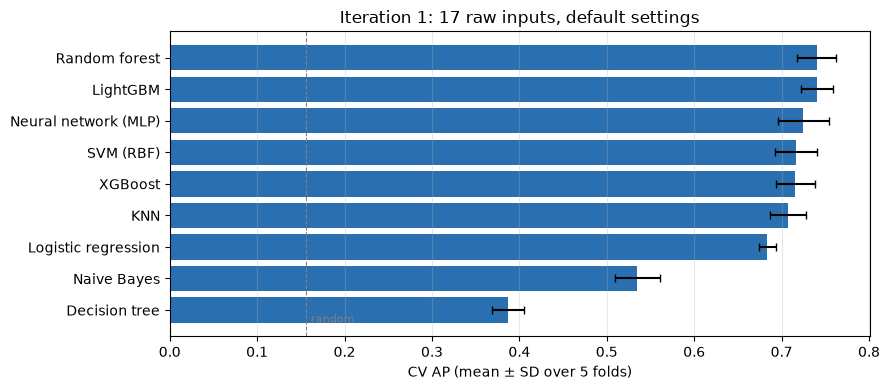

In [3]:
t0 = time.time()
it1 = {'Dummy (purchase rate)': Pipeline([('model', DummyClassifier(strategy='prior'))])}
it1.update({m: make_model(m) for m in MODELS})
cv1, oof1 = cv_many(it1)
show_cv(cv1, pd.Series(FAMILY, name='family'))
print(f'{time.time() - t0:.0f}s')

fig, ax = plt.subplots(figsize=(9, 4))
order = cv1.drop('Dummy (purchase rate)').astype({'AP mean': float}).sort_values('AP mean').index
ax.barh(order, cv1.loc[order, 'AP mean'].astype(float), xerr=cv1.loc[order, 'AP SD'].astype(float), capsize=3, color='#2a6fb0')
ax.axvline(y.mean(), ls='--', c='grey', lw=.8); ax.text(y.mean() + .005, -0.4, 'random', color='grey', fontsize=8)
ax.set(xlabel='CV AP (mean ± SD over 5 folds)', title='Iteration 1: 17 raw inputs, default settings')
ax.grid(alpha=.3, axis='x'); fig.tight_layout(); fig.savefig(OUT / 'iteration1_cv.png', dpi=150); plt.show()

**Result.**
- **Random forest and LightGBM lead** (AP 0.740), and the MLP, SVM, XGBoost and KNN follow within about 0.035. All six are far above random (0.156).
- **Train AP shows two very different behaviors:**
  - Random forest, the decision tree and KNN reach a train AP of 1.0, and XGBoost 0.996. **They memorize the training data at default settings,** which suggests they will gain from regularization in fine-tuning.
  - Logistic regression and naive Bayes have almost the same train and CV AP. **They underfit:** their model form, not overfitting, limits them.
- **The single decision tree is the weakest model (0.387).** Fully grown, it fits noise and outputs almost only 0/1 probabilities, so it ranks sessions poorly. This is the classic reason to average many trees, as random forests and boosting do.
- **Fold SDs are about 0.02,** so differences of less than about 0.02 AP between models are not meaningful.

### 1.1 Most significant variables for each algorithm

**Permutation importance** works the same way for every family, so the families can be compared directly. Each of the 17 raw inputs is shuffled in turn on the validation part of every fold (3 repeats), and the drop in AP is averaged over the 5 folds. Categorical inputs are shuffled as whole variables, before encoding.

27s


,Logistic regression,Naive Bayes,KNN,SVM (RBF),Neural network (MLP),Decision tree,Random forest,XGBoost,LightGBM
PageValues,0.4699,0.2649,0.5065,0.5382,0.5234,0.2244,0.5208,0.5209,0.5442
Month,0.0287,0.0152,0.0209,0.0481,0.0360,0.0255,0.0378,0.0473,0.0509
ExitRates,0.0122,0.0152,0.0132,0.0587,0.0239,0.0407,0.0289,0.0466,0.0446
BounceRates,0.0041,0.0100,0.0048,0.0141,0.0111,0.0362,0.0199,0.0276,0.0209
ProductRelated,-0.0022,-0.0077,0.0217,0.0263,0.0163,0.0234,0.0142,0.0265,0.0200
Administrative,0.0022,-0.0180,0.0060,0.0253,0.0122,0.0250,0.0128,0.0213,0.0168
ProductRelated_Duration,-0.0005,-0.0044,0.0049,0.0173,0.0044,0.0339,0.0080,0.0188,0.0160
VisitorType,0.0075,0.0132,0.0162,0.0077,0.0102,0.0013,0.0086,0.0088,0.0109
TrafficType,0.0085,0.0073,0.0041,0.0063,0.0062,0.0066,0.0059,0.0063,0.0034
Administrative_Duration,0.0064,-0.0183,0.0060,-0.0004,0.0175,0.0170,0.0027,0.0081,0.0050


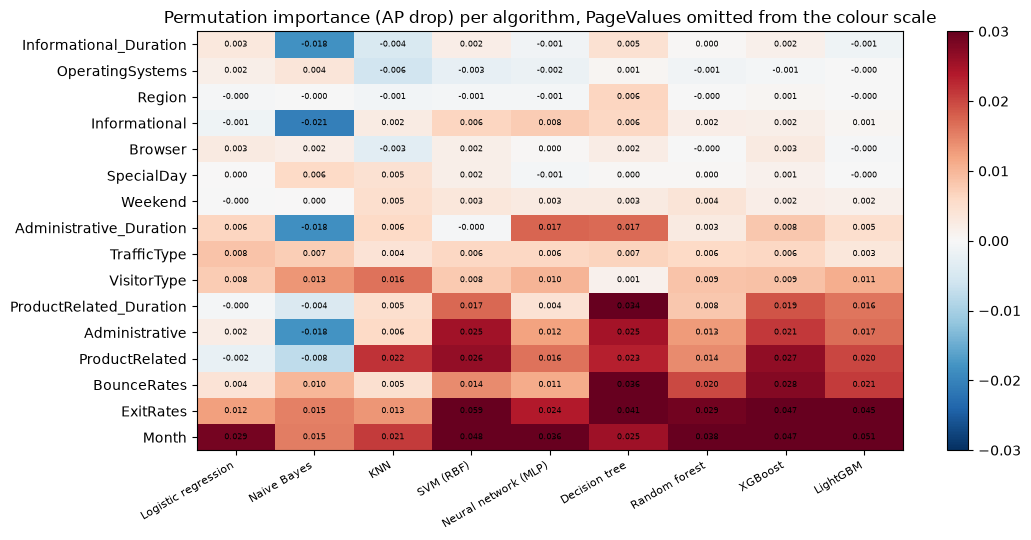

PageValues AP drop per model: {'Logistic regression': 0.47, 'Naive Bayes': 0.265, 'KNN': 0.506, 'SVM (RBF)': 0.538, 'Neural network (MLP)': 0.523, 'Decision tree': 0.224, 'Random forest': 0.521, 'XGBoost': 0.521, 'LightGBM': 0.544}


In [4]:
t0 = time.time()
imp1 = importance_many({m: it1[m] for m in MODELS})
imp1.to_csv(OUT / 'iteration1_permutation_importance.csv')
print(f'{time.time() - t0:.0f}s')
display(imp1.loc[imp1.mean(axis=1).sort_values(ascending=False).index])

fig, ax = plt.subplots(figsize=(11, 5.5))
show_imp = imp1.drop(index='PageValues').loc[imp1.drop(index='PageValues').mean(axis=1).sort_values().index]
im = ax.imshow(show_imp.values, aspect='auto', cmap='RdBu_r', vmin=-0.03, vmax=0.03)
ax.set(yticks=range(len(show_imp)), yticklabels=show_imp.index, xticks=range(len(MODELS)), title=
       'Permutation importance (AP drop) per algorithm, PageValues omitted from the colour scale')
ax.set_xticklabels(MODELS, rotation=30, ha='right', fontsize=8)
for i in range(show_imp.shape[0]):
    for j in range(show_imp.shape[1]):
        ax.text(j, i, f'{show_imp.values[i, j]:.3f}', ha='center', va='center', fontsize=6)
fig.colorbar(im, ax=ax); fig.tight_layout(); fig.savefig(OUT / 'iteration1_importance.png', dpi=150); plt.show()
print('PageValues AP drop per model:', imp1.loc['PageValues'].round(3).to_dict())

**Result.**
- **`PageValues` dominates every algorithm.** Shuffling it lowers AP by 0.47–0.54 for most models (0.26 for naive Bayes, 0.22 for the tree).
- **`Month` (0.015–0.051) and `ExitRates` (0.012–0.059) come next for every model,** then `BounceRates` and the administrative and product-page activity.
- **The algorithms differ in how they use page activity:**
  - The tree models, SVM and KNN use `ProductRelated` and `Administrative`.
  - **Logistic regression gets nothing from `ProductRelated` and its duration**, which have slightly negative importance. Their effect is not linear in the log scale.
  - **Naive Bayes has clearly negative importance for all six count and duration inputs** (−0.004 to −0.021). Because it treats each input as independent evidence, the strongly correlated pages and durations are counted twice, which distorts its probabilities.
- **`Region`, `OperatingSystems`, `Browser` and `Informational_Duration` have importance ≤ 0.003 for almost every model,** so they mainly add noise. This motivates the feature selection in iteration 3.
- Importance is not causal. Correlated inputs also share importance: `ProductRelated` and its duration partly stand in for each other.

### 1.2 Types of errors

For each model, the threshold is set to the value that maximizes F1 on its out-of-fold (OOF) predictions. Each training session is then a true positive (TP), a missed buyer (false negative, FN), a false alarm (false positive, FP) or a true negative (TN). The analysis has three parts:

1. **How many errors of each type** each model makes.
2. **What the errors look like:** median profiles of missed buyers and false alarms.
3. **Whether the models make the *same* errors:** the overlap of their error sets (Jaccard index) and the correlation of their scores. The fewer errors two models share, the more an ensemble of them can gain.

,threshold,F1,missed buyers (FN),false alarms (FP),recall,precision
SVM (RBF),0.1875,0.6810,447.0000,564.0000,0.7071,0.6567
LightGBM,0.2938,0.6810,399.0000,657.0000,0.7385,0.6317
Random forest,0.3367,0.6795,429.0000,606.0000,0.7189,0.6442
Neural network (MLP),0.3435,0.6740,448.0000,595.0000,0.7064,0.6444
Logistic regression,0.2634,0.6730,420.0000,655.0000,0.7248,0.6281
KNN,0.2906,0.6630,389.0000,767.0000,0.7451,0.5972
XGBoost,0.3190,0.6593,480.0000,601.0000,0.6855,0.6351
Naive Bayes,0.6700,0.5922,453.0000,1025.0000,0.7031,0.5114
Decision tree,1.0000,0.5658,653.0000,687.0000,0.5721,0.5596


sessions  median PageValues  share PageValues = 0  median product pages  median exit rate  share returning visitors  share November
reference           all buyers     1526.0000            16.3592                0.1953               29.0000            0.0163                    0.7765          0.3925
                    all non-buyers 8238.0000             0.0000                0.8836               16.0000            0.0285                    0.8694          0.2135
Logistic regression FN              420.0000             0.0000                0.7048               32.0000            0.0224                    0.8333          0.4952
                    FP              655.0000            16.3798                0.0229               39.0000            0.0186                    0.9191          0.3221
Naive Bayes         FN              453.0000             0.0000                0.5563               20.0000            0.0250                    0.8411          0.4018
                    FP             1025.0000             7.4359                0.2702               48.0000            0.0161                    0.8576          0.3180
KNN                 FN              389.0000             0.0000                0.6992               30.0000            0.0219                    0.8123          0.4859
                    FP              767.0000            12.6534                0.1056               45.0000            0.0193                    0.9439          0.3468
SVM (RBF)           FN              447.0000             0.0000                0.6667               37.0000            0.0220                    0.8389          0.4720
                    FP              564.0000            16.3657                0.0071               38.5000            0.0191                    0.9309          0.3546
Random forest       FN              429.0000             0.0000                0.6527               33.0000            0.0232                    0.8368          0.4569
                    FP              606.0000            14.6883                0.0825               40.0000            0.0173                    0.9175          0.3845
LightGBM            FN              399.0000             0.0000                0.6717               32.0000            0.0224                    0.8296          0.4561
                    FP              657.0000            11.8406                0.1400               40.0000            0.0190                    0.9102          0.4018

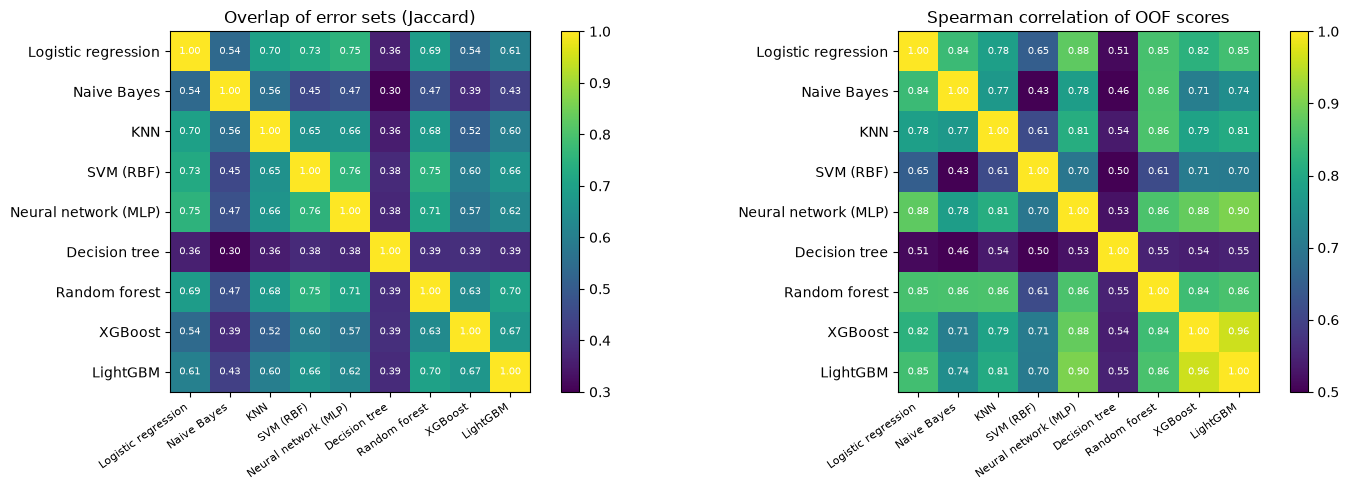

Sessions misclassified by both RF and LightGBM: 861 (70% of their combined errors); by every one of the 9 models: 371


In [5]:
def error_analysis(oof, models):
    rows, errors = {}, {}
    for m in models:
        t, f1 = max_f1_threshold(oof[m])
        pred = oof[m] >= t
        fn, fp = (y == 1) & ~pred, (y == 0) & pred
        errors[m] = fn | fp
        rows[m] = {'threshold': t, 'F1': f1, 'missed buyers (FN)': int(fn.sum()), 'false alarms (FP)': int(fp.sum()),
                   'recall': ((y == 1) & pred).sum() / (y == 1).sum(), 'precision': ((y == 1) & pred).sum() / pred.sum()}
    counts = pd.DataFrame(rows).T
    jac = pd.DataFrame({a: {b: (errors[a] & errors[b]).sum() / (errors[a] | errors[b]).sum() for b in models}
                        for a in models})
    corr = pd.DataFrame({m: oof[m] for m in models}).corr(method='spearman')
    return counts, jac, corr, errors


def error_profiles(oof, models):
    prof = {}
    for m in models:
        t, _ = max_f1_threshold(oof[m])
        pred = oof[m] >= t
        for label, mask in [('FN', (y == 1) & ~pred), ('FP', (y == 0) & pred)]:
            g = train[mask]
            prof[(m, label)] = {'sessions': int(mask.sum()), 'median PageValues': g['PageValues'].median(),
                                'share PageValues = 0': (g['PageValues'] == 0).mean(),
                                'median product pages': g['ProductRelated'].median(),
                                'median exit rate': g['ExitRates'].median(),
                                'share returning visitors': (g['VisitorType'] == 'Returning_Visitor').mean(),
                                'share November': (g['Month'] == 'Nov').mean()}
    ref = {}
    for label, mask in [('all buyers', y == 1), ('all non-buyers', y == 0)]:
        g = train[mask]
        ref[('reference', label)] = {'sessions': int(mask.sum()), 'median PageValues': g['PageValues'].median(),
                                     'share PageValues = 0': (g['PageValues'] == 0).mean(),
                                     'median product pages': g['ProductRelated'].median(),
                                     'median exit rate': g['ExitRates'].median(),
                                     'share returning visitors': (g['VisitorType'] == 'Returning_Visitor').mean(),
                                     'share November': (g['Month'] == 'Nov').mean()}
    return pd.DataFrame({**ref, **prof}).T


err1, jac1, corr1, errors1 = error_analysis(oof1, MODELS)
display(err1.sort_values('F1', ascending=False))
display(error_profiles(oof1, ['Logistic regression', 'Naive Bayes', 'KNN', 'SVM (RBF)', 'Random forest', 'LightGBM']))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, mat, title in [(axes[0], jac1, 'Overlap of error sets (Jaccard)'), (axes[1], corr1, 'Spearman correlation of OOF scores')]:
    im = ax.imshow(mat.values, cmap='viridis', vmin=0.3 if 'Jaccard' in title else 0.5, vmax=1)
    ax.set(xticks=range(len(MODELS)), yticks=range(len(MODELS)), yticklabels=MODELS, title=title)
    ax.set_xticklabels(MODELS, rotation=35, ha='right', fontsize=8)
    for i in range(len(MODELS)):
        for j in range(len(MODELS)):
            ax.text(j, i, f'{mat.values[i, j]:.2f}', ha='center', va='center', fontsize=7, color='w')
    fig.colorbar(im, ax=ax)
fig.tight_layout(); fig.savefig(OUT / 'iteration1_error_overlap.png', dpi=150); plt.show()

both = errors1['Random forest'] & errors1['LightGBM']
print(f'Sessions misclassified by both RF and LightGBM: {both.sum()} '
      f'({both.sum() / (errors1["Random forest"] | errors1["LightGBM"]).sum():.0%} of their combined errors); '
      f'by every one of the 9 models: {np.logical_and.reduce([errors1[m] for m in MODELS]).sum()}')

**Result.**
- **How many errors.** At their max-F1 thresholds, the seven stronger models reach F1 0.66–0.68. Each misses 390–480 of the 1,526 buyers and raises 560–770 false alarms. Naive Bayes raises the most false alarms (1,025), and the tree misses the most buyers (653).
- **Missed buyers (FN) look like non-buyers on the key signal.** Their median `PageValues` is 0, and 65–70 % of them have `PageValues = 0`, against only 20 % of all buyers. They viewed about as many product pages as typical buyers (30–37 for most models, 20 for naive Bayes). They are more often in **November** (40–50 % against 39 % of buyers), when many people buy in a single, direct session.
- **False alarms (FP) look like buyers.** They have a high `PageValues` (median 12–16, 7 for naive Bayes), long product browsing (38–48 product pages, against 16 for typical non-buyers), low exit rates, and are **86–94 % returning visitors**: comparison shoppers who came back, browsed seriously and still did not buy.
- **The models largely make the same errors:**
  - Random forest and LightGBM share 70 % of their errors.
  - Pairwise error overlaps between the stronger models are 0.52–0.76 (Jaccard index). The scores of XGBoost and LightGBM are correlated at 0.96, and those of the other strong models at 0.61–0.90.
  - **371 sessions are misclassified by all nine models.**

  Combining the models can therefore only fix the minority of errors on which they disagree. The models whose errors overlap least are the most useful partners.

### 1.3 What data would a human have used to avoid these errors?

The errors in §1.2 occur where the recorded signals, mainly `PageValues`, point the wrong way. A human analyst would look at information this data set does not contain:

| Error type | What it typically is | Data a human would use |
|---|---|---|
| **Missed buyer with `PageValues = 0`** | A returning customer who knows what they want and goes straight to the product and checkout. Typical in November, for example Black Friday. | **Cart and checkout events** (add-to-cart, checkout started, payment page reached), the **customer's purchase history** and loyalty status, and campaign or coupon codes that brought them in |
| **False alarm with long browsing and high `PageValues`** | A comparison shopper or someone planning a later purchase: they browse many product pages but leave. | **Cart abandonment and the step where they left**, visits to shipping-cost and return-policy pages, **prices and price changes, stock availability**, and search queries such as "compare" or "review" |
| **Errors shared by all models** | Sessions whose recorded behavior is identical for buyers and non-buyers. | **Who** the visitor is (logged-in user ID, previous sessions) and the **order of events within the session**. The data only has session totals, not the clickstream. |

These data are not available in the UCI data set, so they are listed as an improvement path in §7.

## 2 · `PageValues`: Leakage Check

`PageValues` is the Google Analytics "page value": the transaction revenue credited to the pages a visitor saw before buying, averaged over the pages of the session. The leakage question is whether a session's value already reflects **its own** purchase. Three checks are possible with the data:

1. If the value were computed from the session's own transaction, **every buying session would have PageValues > 0**.
2. Non-buyers with PageValues > 0 show that the value comes from *other* visitors' purchases on the same pages, which is a page-level, historical quantity.
3. How much each model depends on it: CV without `PageValues`, same settings.

In [6]:
pv = train['PageValues'] > 0
display(pd.crosstab(train[TARGET].map({0: 'no purchase', 1: 'purchase'}), pv.map({False: 'PageValues = 0', True: 'PageValues > 0'}),
                    margins=True))
print(f'Buyers with PageValues = 0: {1 - pv[y == 1].mean():.1%} | non-buyers with PageValues > 0: {pv[y == 0].mean():.1%}')
print(f'P(purchase | PageValues > 0) = {y[pv].mean():.3f}   P(purchase | PageValues = 0) = {y[~pv].mean():.3f}')

t0 = time.time()
cv1_nopv, _ = cv_many({m: make_model(m, include_pv=False) for m in MODELS})
pv_table = pd.DataFrame({'AP with PageValues': cv1.loc[MODELS, 'AP mean'].astype(float),
                         'AP without PageValues': cv1_nopv.loc[MODELS, 'AP mean'].astype(float),
                         'SD without': cv1_nopv.loc[MODELS, 'AP SD'].astype(float)})
pv_table['share of AP above random kept'] = (pv_table['AP without PageValues'] - y.mean()) / (pv_table['AP with PageValues'] - y.mean())
display(pv_table.sort_values('AP with PageValues', ascending=False))
pv_table.to_csv(OUT / 'pagevalues_check.csv')
print(f'{time.time() - t0:.0f}s')

PageValues,PageValues = 0,PageValues > 0,All
Revenue,,,
no purchase,7279,959,8238
purchase,298,1228,1526
All,7577,2187,9764


Buyers with PageValues = 0: 19.5% | non-buyers with PageValues > 0: 11.6%
P(purchase | PageValues > 0) = 0.561   P(purchase | PageValues = 0) = 0.039


,AP with PageValues,AP without PageValues,SD without,share of AP above random kept
Random forest,0.7404,0.3700,0.0250,0.3659
LightGBM,0.7402,0.3623,0.0205,0.3528
Neural network (MLP),0.7248,0.3487,0.0324,0.3384
SVM (RBF),0.7169,0.3271,0.0176,0.3046
XGBoost,0.7156,0.3439,0.0210,0.3354
KNN,0.7068,0.3184,0.0181,0.2945
Logistic regression,0.6836,0.3391,0.0250,0.3466
Naive Bayes,0.5351,0.3117,0.0223,0.4102
Decision tree,0.3873,0.1878,0.0139,0.1365


16s


**Result.**
- **`PageValues` is not a copy of the outcome.**
  - 19.5 % of buyers (298 sessions) have `PageValues = 0`. A value computed from the session's own transaction would be positive for every buyer.
  - 11.6 % of non-buyers have a positive value. This fits Google Analytics' definition: a page's value is the revenue of *all* visitors who later bought after seeing that page, averaged over its views, and a session gets the average of the values of the pages it visited.
- **Indirect leakage is still possible.** If these page values were computed over the same period as the data, they include the purchases of the sessions themselves, including test sessions. That works like target encoding fitted on all the data, and it would inflate the scores.
- **Strength of the signal.** A session with `PageValues > 0` buys 56 % of the time, against 4 % for one without.
- **Dependence of the models.** Without `PageValues`, every model falls to AP 0.31–0.37 and keeps only 29–37 % of its gain over random (naive Bayes 41 %, the tree 14 %).
- **The ranking is stable without it:** random forest (0.370) and LightGBM (0.362) stay on top, followed by the MLP, XGBoost and logistic regression. The shortlist below is therefore the same under either policy.
- **Group decision:** the main analysis keeps `PageValues`. The risk is listed in §7 (Assumptions and Limitations), together with its likely impact and how it could be removed.

## 3 · Iteration 2: Feature Engineering

The first iteration showed what drives the models. The analysis in §1.1–1.2 suggests that missed buyers and false alarms are separated mainly by *how* a session browsed: depth, time per page and focus on product pages. Iteration 2 therefore adds the EDA notebook's **12 session-level features**:

- **Totals:** total pages and total duration.
- **Averages:** average time per page, and per product, administrative and informational page.
- **Shares:** the share of product pages and the share of product time.
- **Flags:** no tracked pages, zero-duration session, any informational and any administrative visit.

All other choices stay as in iteration 1. The paired difference on the same folds shows whether a change is larger than the fold-to-fold noise.

In [7]:
t0 = time.time()
cv2, oof2 = cv_many({m: make_model(m, engineered=True) for m in MODELS})
d = {m: cv2.loc[m, 'fold AP'] - cv1.loc[m, 'fold AP'] for m in MODELS}
it2_table = pd.DataFrame({'AP iteration 1 (raw)': cv1.loc[MODELS, 'AP mean'].astype(float),
                          'AP iteration 2 (+12 engineered)': cv2.loc[MODELS, 'AP mean'].astype(float),
                          'paired change': {m: v.mean() for m, v in d.items()},
                          'SD of change': {m: v.std(ddof=1) for m, v in d.items()},
                          'folds improved': {m: f'{(v > 0).sum()}/5' for m, v in d.items()}})
display(it2_table.sort_values('AP iteration 2 (+12 engineered)', ascending=False))
print(f'{time.time() - t0:.0f}s')

,AP iteration 1 (raw),AP iteration 2 (+12 engineered),paired change,SD of change,folds improved
LightGBM,0.7402,0.7404,0.0002,0.0077,2/5
Random forest,0.7404,0.7311,-0.0093,0.0070,1/5
XGBoost,0.7156,0.7185,0.0029,0.0224,2/5
SVM (RBF),0.7169,0.7124,-0.0045,0.0076,1/5
Neural network (MLP),0.7248,0.7060,-0.0188,0.0401,1/5
KNN,0.7068,0.6999,-0.0069,0.0064,1/5
Logistic regression,0.6836,0.6823,-0.0013,0.0073,3/5
Naive Bayes,0.5351,0.4446,-0.0905,0.0070,0/5
Decision tree,0.3873,0.3776,-0.0098,0.0210,1/5


11s


**Result.**
- **The engineered features do not help any model beyond noise.**
  - LightGBM (+0.0002) and XGBoost (+0.003) are unchanged within fold noise: they improved in only 2 of 5 folds.
  - Random forest (−0.009), KNN (−0.007), SVM (−0.005) and the MLP (−0.019) get slightly worse.
  - **Naive Bayes falls sharply (−0.091),** because the totals and averages repeat the information of the page counts and durations, which it then counts once more.
- **The explanation is redundancy.** The features are simple combinations of existing columns that trees can already split on. For distance-based and kernel models, they add redundant dimensions that give browsing depth extra weight in the distance.
- The engineered features are kept only for the two boosting models, where they did not hurt, and are tested again in iteration 3.

## 4 · Iteration 3: Feature Selection

The importance analysis showed that some inputs are useless or even harmful for some algorithms (negative permutation importance, meaning AP *rises* when the input is shuffled). For example, naive Bayes counts correlated page counts and durations twice. Iteration 3 is a quick **per-algorithm selection**:

- **3a, drop harmful or useless inputs.** Drop every raw input whose iteration-1 importance for that model is **≤ 0**, keeping `PageValues` (the group policy). The selection is applied on top of the model's better feature set from iterations 1–2.
- **3b, 3a plus rare-category grouping.** Category levels seen in fewer than 1 % of the training fold are merged. This mainly affects `Browser`, `OperatingSystems` and `TrafficType`, which have many rare codes.

The rule uses importances estimated on the same folds, so it is slightly optimistic. Each model's **final feature configuration** is the best of iterations 1, 2, 3a and 3b by CV AP.

In [8]:
best12 = {m: bool(cv2.loc[m, 'AP mean'] > cv1.loc[m, 'AP mean']) for m in MODELS}     # engineered features helped?
DROP = {m: tuple(f for f in FEATURES if imp1.loc[f, m] <= 0 and f != 'PageValues') for m in MODELS}
display(pd.DataFrame({'uses engineered features': best12, 'inputs dropped in 3a': {m: ', '.join(v) or '-' for m, v in DROP.items()}}))

t0 = time.time()
configs3 = {}
for m in MODELS:
    configs3[(m, '3a')] = make_model(m, engineered=best12[m], drop=DROP[m])
    configs3[(m, '3b')] = make_model(m, engineered=best12[m], drop=DROP[m], rare=True)
cv3, oof3 = cv_many(configs3)
print(f'{time.time() - t0:.0f}s')

CONFIG = {}
rows = {}
for m in MODELS:
    options = {'1 raw': (cv1.loc[m], dict(engineered=False, drop=(), rare=False), oof1[m]),
               '2 +engineered': (cv2.loc[m], dict(engineered=True, drop=(), rare=False), oof2[m]),
               '3a selection': (cv3.loc[[(m, '3a')]].iloc[0], dict(engineered=best12[m], drop=DROP[m], rare=False),
                                oof3[(m, '3a')]),
               '3b selection + rare grouping': (cv3.loc[[(m, '3b')]].iloc[0],
                                                dict(engineered=best12[m], drop=DROP[m], rare=True), oof3[(m, '3b')])}
    best = max(options, key=lambda k: float(options[k][0]['AP mean']))
    CONFIG[m] = {'iteration': best, **options[best][1], 'oof': options[best][2], 'fold AP': options[best][0]['fold AP'],
                 'AP mean': float(options[best][0]['AP mean']), 'AP SD': float(options[best][0]['AP SD']),
                 'Train AP': float(options[best][0]['Train AP'])}
    rows[m] = {**{k: float(v[0]['AP mean']) for k, v in options.items()}, 'best': best}
iterations = pd.DataFrame(rows).T
display(iterations.sort_values('3b selection + rare grouping', ascending=False))
iterations.to_csv(OUT / 'iterations_cv_ap.csv')

,uses engineered features,inputs dropped in 3a
Logistic regression,False,"Informational, ProductRelated, ProductRelated_..."
Naive Bayes,False,"Administrative, Administrative_Duration, Infor..."
KNN,False,"Informational_Duration, OperatingSystems, Brow..."
SVM (RBF),False,"Administrative_Duration, OperatingSystems, Region"
Neural network (MLP),False,"Informational_Duration, SpecialDay, OperatingS..."
Decision tree,False,-
Random forest,False,"OperatingSystems, Browser, Region"
XGBoost,True,OperatingSystems
LightGBM,True,"Informational_Duration, SpecialDay, OperatingS..."


14s


,1 raw,2 +engineered,3a selection,3b selection + rare grouping,best
Random forest,0.7404,0.7311,0.7435,0.7452,3b selection + rare grouping
LightGBM,0.7402,0.7404,0.7387,0.7383,2 +engineered
SVM (RBF),0.7169,0.7124,0.7285,0.7289,3b selection + rare grouping
Neural network (MLP),0.7248,0.7060,0.7400,0.7251,3a selection
KNN,0.7068,0.6999,0.7233,0.7234,3b selection + rare grouping
XGBoost,0.7156,0.7185,0.7235,0.7197,3a selection
Logistic regression,0.6836,0.6823,0.6846,0.6842,3a selection
Naive Bayes,0.5351,0.4446,0.6595,0.6578,3a selection
Decision tree,0.3873,0.3776,0.3873,0.3838,1 raw


**Result.** The selection rule removes inputs whose importance was ≤ 0 for that model:

| Model | Inputs dropped |
|---|---|
| Random forest | `OperatingSystems`, `Browser`, `Region` |
| XGBoost | `OperatingSystems` |
| LightGBM | `Informational_Duration`, `SpecialDay`, `OperatingSystems`, `Browser`, `Region` |
| KNN | `Informational_Duration`, `OperatingSystems`, `Browser`, `Region` |
| MLP | `Informational_Duration`, `SpecialDay`, `OperatingSystems`, `Region` |
| SVM | `Administrative_Duration`, `OperatingSystems`, `Region` |
| Logistic regression | `Informational`, `ProductRelated`, `ProductRelated_Duration`, `Region`, `Weekend` |
| Naive Bayes | All six page-count and duration inputs, plus `Region` |
| Decision tree | Nothing |

- **Feature selection helps most models:**
  - **KNN +0.017** (0.707 → 0.723) and **SVM +0.012** (0.717 → 0.729). Distance- and kernel-based models suffer most from noisy dimensions, because every input counts in the distance.
  - **MLP +0.015** (0.725 → 0.740), although it is the least stable model (fold SD 0.033).
  - **XGBoost +0.008** and **random forest +0.005** (RF best with rare-category grouping: 0.745).
  - **Naive Bayes +0.124** (0.535 → 0.660), the clearest effect, confirming the double-counting explanation from §1.1.
- **LightGBM is the exception:** dropping its five inputs lowers AP slightly (−0.002), so its best configuration remains iteration 2.
- **Rare-category grouping adds at most +0.002,** and for the MLP it costs 0.015. It is kept only where it was best (RF, SVM, KNN).
- **Caveat:** the inputs were chosen with importances from the same folds, so these gains are slightly optimistic. The fine-tuning notebook re-checks everything on 15 fresh folds.

## 5 · Repeating the Analysis on the Final Feature Configurations

The course asks for one or two more rounds of the analysis steps. This section re-runs them for every model at its final feature configuration: CV mean ± SD, variable importance, error types and error overlap.

,family,feature configuration,engineered,dropped,rare grouping,AP mean,AP SD,Train AP,AP iteration 1,change vs iteration 1
Random forest,bagged trees,3b selection + rare grouping,False,"OperatingSystems, Browser, Region",True,0.7452,0.0235,1.0000,0.7404,0.0048
LightGBM,boosted trees,2 +engineered,True,-,False,0.7404,0.0247,0.9793,0.7402,0.0002
Neural network (MLP),neural network,3a selection,False,"Informational_Duration, SpecialDay, OperatingS...",False,0.7400,0.0325,0.7803,0.7248,0.0151
SVM (RBF),kernel,3b selection + rare grouping,False,"Administrative_Duration, OperatingSystems, Region",True,0.7289,0.0240,0.7972,0.7169,0.0120
XGBoost,boosted trees,3a selection,True,OperatingSystems,False,0.7235,0.0236,0.9991,0.7156,0.0079
KNN,instance-based,3b selection + rare grouping,False,"Informational_Duration, OperatingSystems, Brow...",True,0.7234,0.0275,1.0000,0.7068,0.0166
Logistic regression,linear,3a selection,False,"Informational, ProductRelated, ProductRelated_...",False,0.6846,0.0116,0.6946,0.6836,0.0010
Naive Bayes,probabilistic,3a selection,False,"Administrative, Administrative_Duration, Infor...",False,0.6595,0.0138,0.6649,0.5351,0.1244
Decision tree,single tree,1 raw,False,-,False,0.3873,0.0185,1.0000,0.3873,0.0000


importance: 18s


,1st,2nd,3rd,4th
Logistic regression,PageValues (0.471),Month (0.030),ExitRates (0.022),Administrative_Duration (0.007)
Naive Bayes,PageValues (0.420),ExitRates (0.027),Month (0.017),BounceRates (0.016)
KNN,PageValues (0.523),Month (0.035),ProductRelated (0.024),VisitorType (0.019)
SVM (RBF),PageValues (0.547),ExitRates (0.065),Month (0.059),ProductRelated (0.032)
Neural network (MLP),PageValues (0.537),Month (0.044),ExitRates (0.025),ProductRelated (0.024)
Decision tree,PageValues (0.224),ExitRates (0.041),BounceRates (0.036),ProductRelated_Duration (0.034)
Random forest,PageValues (0.536),Month (0.042),ExitRates (0.028),BounceRates (0.017)
XGBoost,PageValues (0.530),Month (0.048),ExitRates (0.040),ProductRelated (0.030)
LightGBM,PageValues (0.544),Month (0.049),ExitRates (0.035),ProductRelated (0.030)


,threshold,F1,missed buyers (FN),false alarms (FP),recall,precision
SVM (RBF),0.1291,0.6859,394.0000,643.0000,0.7418,0.6377
Random forest,0.3733,0.6809,461.0000,537.0000,0.6979,0.6648
Neural network (MLP),0.3436,0.6775,422.0000,629.0000,0.7235,0.6370
LightGBM,0.2438,0.6739,352.0000,784.0000,0.7693,0.5996
Logistic regression,0.2641,0.6734,425.0000,643.0000,0.7215,0.6313
XGBoost,0.2759,0.6712,438.0000,628.0000,0.7130,0.6340
KNN,0.3904,0.6658,483.0000,564.0000,0.6835,0.6490
Naive Bayes,0.6282,0.6516,489.0000,620.0000,0.6796,0.6258
Decision tree,1.0000,0.5658,653.0000,687.0000,0.5721,0.5596


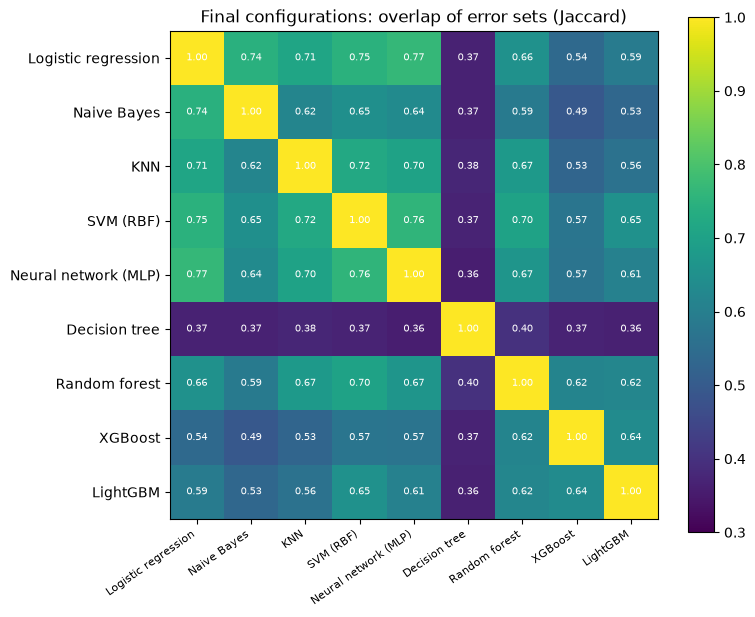

In [9]:
final = pd.DataFrame({m: {'family': FAMILY[m], 'feature configuration': CONFIG[m]['iteration'],
                          'engineered': CONFIG[m]['engineered'], 'dropped': ', '.join(CONFIG[m]['drop']) or '-',
                          'rare grouping': CONFIG[m]['rare'], 'AP mean': CONFIG[m]['AP mean'], 'AP SD': CONFIG[m]['AP SD'],
                          'Train AP': CONFIG[m]['Train AP'], 'AP iteration 1': float(cv1.loc[m, 'AP mean'])}
                      for m in MODELS}).T.sort_values('AP mean', ascending=False)
final['change vs iteration 1'] = final['AP mean'].astype(float) - final['AP iteration 1'].astype(float)
display(final)
final.to_csv(OUT / 'final_feature_configurations.csv')

final_models = {m: make_model(m, engineered=CONFIG[m]['engineered'], drop=CONFIG[m]['drop'], rare=CONFIG[m]['rare'])
                for m in MODELS}
t0 = time.time()
imp_final = importance_many(final_models)
imp_final.to_csv(OUT / 'final_permutation_importance.csv')
print(f'importance: {time.time() - t0:.0f}s')
top3 = pd.DataFrame({m: [f'{f} ({imp_final.loc[f, m]:.3f})' for f in imp_final[m].sort_values(ascending=False).index[:4]]
                     for m in MODELS}, index=['1st', '2nd', '3rd', '4th']).T
display(top3)

oof_final = {m: CONFIG[m]['oof'] for m in MODELS}
err_f, jac_f, corr_f, errors_f = error_analysis(oof_final, MODELS)
display(err_f.sort_values('F1', ascending=False))
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(jac_f.values, cmap='viridis', vmin=0.3, vmax=1)
ax.set(xticks=range(len(MODELS)), yticks=range(len(MODELS)), yticklabels=MODELS, title='Final configurations: overlap of error sets (Jaccard)')
ax.set_xticklabels(MODELS, rotation=35, ha='right', fontsize=8)
for i in range(len(MODELS)):
    for j in range(len(MODELS)):
        ax.text(j, i, f'{jac_f.values[i, j]:.2f}', ha='center', va='center', fontsize=7, color='w')
fig.colorbar(im, ax=ax); fig.tight_layout(); fig.savefig(OUT / 'final_error_overlap.png', dpi=150); plt.show()

**Result of the second analysis round.**
- **The importance ranking is stable:** `PageValues`, then `Month` and `ExitRates`, are the top three inputs for every model, so feature selection did not change *what* the models rely on.
- **Naive Bayes now ranks `ExitRates` and `BounceRates` second and fourth.** Without the double-counted page inputs, its probabilities are less extreme, and its false alarms fall from 1,025 to 620.
- **The models make different *kinds* of errors at their max-F1 thresholds:**
  - **LightGBM is recall-oriented:** it misses the fewest buyers (352) but raises the most false alarms (784).
  - **Random forest is precision-oriented:** 461 missed buyers, but only 537 false alarms.
  - **KNN** (483 missed buyers / 564 false alarms) and the **MLP** (422 / 629) lie in between.

  These different trade-offs are what an ensemble can exploit.
- **Error overlaps** between the stronger models are 0.58–0.68 (Jaccard index). Pairs below the average are the most complementary, which is the basis of the shortlist rule below.

## 6 · Shortlist

**Rule (stated before reading the result):**
1. **Candidates.** Every model whose CV AP is within one fold SD of the best model. Differences that small are within fold-to-fold noise, so these models count as equally good. If fewer than three qualify, the window widens to 0.05 AP.
2. **Start** with the best model.
3. **Add diverse partners.** Repeatedly add the candidate whose errors overlap *least* with the models already chosen (lowest mean Jaccard index of the error sets), until five models are chosen or no candidates remain. This follows the course's advice to prefer models that make different types of errors.

In [10]:
best_m = final['AP mean'].astype(float).idxmax()
best_ap, best_sd = CONFIG[best_m]['AP mean'], CONFIG[best_m]['AP SD']
candidates = [m for m in MODELS if CONFIG[m]['AP mean'] >= best_ap - best_sd]
if len(candidates) < 3:
    candidates = [m for m in MODELS if CONFIG[m]['AP mean'] >= best_ap - 0.05]
SHORTLIST, steps = [best_m], []
remaining = [m for m in candidates if m != best_m]
while remaining and len(SHORTLIST) < 5:
    overlap = {m: float(np.mean([jac_f.loc[m, s_] for s_ in SHORTLIST])) for m in remaining}
    pick = min(remaining, key=lambda m: (overlap[m], -CONFIG[m]['AP mean']))
    steps.append({'step': len(SHORTLIST) + 1, 'added': pick, 'mean error overlap with chosen': overlap[pick],
                  'CV AP': CONFIG[pick]['AP mean'],
                  'other candidates (overlap)': ', '.join(f'{m} ({v:.3f})' for m, v in sorted(overlap.items(), key=lambda kv: kv[1]) if m != pick)})
    SHORTLIST.append(pick); remaining.remove(pick)
print('Best model:', best_m, f'(AP {best_ap:.4f} ± {best_sd:.4f})')
print('Candidates within 1 SD:', candidates)
display(pd.DataFrame(steps).set_index('step'))
print('SHORTLIST:', SHORTLIST, '| not chosen:', remaining)
group = SHORTLIST

summary = final.loc[MODELS, ['family', 'feature configuration', 'AP mean', 'AP SD', 'Train AP']].copy()
summary['AP without PageValues'] = pv_table['AP without PageValues']
summary['mean error overlap with group'] = {m: float(np.mean([jac_f.loc[m, g] for g in group if g != m] or [np.nan])) for m in MODELS}
summary['shortlisted'] = [m in SHORTLIST for m in MODELS]
display(summary.sort_values('AP mean', ascending=False))
summary.to_csv(OUT / 'shortlist_table.csv')

json.dump({m: {'engineered': CONFIG[m]['engineered'], 'drop': list(CONFIG[m]['drop']), 'rare': CONFIG[m]['rare'],
               'cv_ap': CONFIG[m]['AP mean'], 'cv_ap_sd': CONFIG[m]['AP SD']} for m in SHORTLIST},
          open(OUT / 'shortlist.json', 'w'), indent=2)
print('Saved', OUT / 'shortlist.json')

Best model: Random forest (AP 0.7452 ± 0.0235)
Candidates within 1 SD: ['KNN', 'SVM (RBF)', 'Neural network (MLP)', 'Random forest', 'XGBoost', 'LightGBM']


,added,mean error overlap with chosen,CV AP,other candidates (overlap)
step,,,,
2,XGBoost,0.6163,0.7235,"LightGBM (0.622), Neural network (MLP) (0.666)..."
3,KNN,0.6019,0.7234,"Neural network (MLP) (0.617), LightGBM (0.630)..."
4,LightGBM,0.6075,0.7404,"Neural network (MLP) (0.646), SVM (RBF) (0.667)"
5,Neural network (MLP),0.6363,0.7400,SVM (RBF) (0.664)


SHORTLIST: ['Random forest', 'XGBoost', 'KNN', 'LightGBM', 'Neural network (MLP)'] | not chosen: ['SVM (RBF)']


,family,feature configuration,AP mean,AP SD,Train AP,AP without PageValues,mean error overlap with group,shortlisted
Random forest,bagged trees,3b selection + rare grouping,0.7452,0.0235,1.0000,0.3700,0.6446,True
LightGBM,boosted trees,2 +engineered,0.7404,0.0247,0.9793,0.3623,0.6077,True
Neural network (MLP),neural network,3a selection,0.7400,0.0325,0.7803,0.3487,0.6363,True
SVM (RBF),kernel,3b selection + rare grouping,0.7289,0.0240,0.7972,0.3271,0.6825,False
XGBoost,boosted trees,3a selection,0.7235,0.0236,0.9991,0.3439,0.5879,True
KNN,instance-based,3b selection + rare grouping,0.7234,0.0275,1.0000,0.3184,0.6173,True
Logistic regression,linear,3a selection,0.6846,0.0116,0.6946,0.3391,0.6525,False
Naive Bayes,probabilistic,3a selection,0.6595,0.0138,0.6649,0.3117,0.5740,False
Decision tree,single tree,1 raw,0.3873,0.0185,1.0000,0.1878,0.3742,False


Saved model_comparison_results\shortlist.json


**Shortlist: random forest, XGBoost, KNN, LightGBM, neural network (MLP).**

| Model | CV AP | Why it is on the list |
|---|---|---|
| **Random forest** | 0.745 ± 0.024 | **Best model.** Precision-oriented errors. Clearly overfits at default settings (train AP 1.0), so it should benefit from tuning. |
| **XGBoost** | 0.724 ± 0.024 | Its errors overlap least with the random forest's (0.616), even though it is also tree-based: boosting corrects errors step by step, while bagging averages independent trees. It also overfits at default settings (train AP 0.999), with clear room for tuning. |
| **KNN** | 0.723 ± 0.027 | A different family (instance-based) with the lowest error overlap with RF and XGBoost (0.602). It judges a session by similar sessions, not by thresholds on single inputs. |
| **LightGBM** | 0.740 ± 0.025 | Second-best score, recall-oriented errors. |
| **Neural network (MLP)** | 0.740 ± 0.033 | Comparable score, another different family. It learns smooth interactions between inputs instead of axis-parallel splits. |

**Not shortlisted:**
- **SVM (0.729)** is within one fold SD of the best, but its errors overlap most with the five chosen models (0.664), so it adds the least to an ensemble.
- **Logistic regression (0.685), naive Bayes (0.660) and the decision tree (0.387)** are more than 0.05 AP behind. For logistic regression and naive Bayes the gap is structural (linear boundary, independence assumption). The single tree is inherently unstable.

The shortlist covers four families (bagging, boosting, instance-based and neural networks), and **it is the same with or without `PageValues`**: these models are also the strongest in the without-`PageValues` check in §2.

## 7 · Assumptions and Limitations

| # | Assumption or limitation | Likely impact | How it could be addressed |
|---|---|---|---|
| 1 | **`PageValues` is assumed to be available at prediction time and free of leakage.** It is not a copy of the outcome (19.5 % of buyers have value 0), but the Google Analytics page values were probably computed over the same period, which includes the sessions' own purchases. | If it leaks, performance is overstated by about a factor of two (AP ≈ 0.74 with it against ≈ 0.37 without). A deployed model would score closer to the without-`PageValues` results. | Ask the data owner how and over which window the page values were computed. Compute page values from an **earlier period only** (a historical lookup table). Report the without-`PageValues` model as a lower bound, as done in §2. |
| 2 | **Sessions are assumed to be independent and representative of future traffic** (random 80/20 split of one year). | Repeat visitors can appear in both training and validation data, and seasonal patterns (November, special days) may shift, so the CV estimates are likely optimistic for future periods. | Validate **by time**, training on earlier months and testing on later ones, and **by user** once visitor IDs are available. Monitor performance after deployment. |
| 3 | **Features describe the whole session** (total durations, final exit and bounce rates). | The model can only score a session after it ends, so it cannot yet trigger an intervention during a visit. | Rebuild the features from **partial sessions** (the first n pages or minutes) using clickstream logs, and retrain. |
| 4 | **The comparison uses default hyperparameters.** | The ranking could change after tuning: the models that overfit at defaults (RF, XGBoost, KNN) may gain most. | The shortlist uses a one-SD window instead of only the top score. The shortlisted models are tuned in `fine_tuning_models.ipynb`. |
| 5 | **Feature selection used importances estimated on the same folds that evaluate it.** | The iteration-3 gains (+0.005 to +0.017 for most models) are slightly optimistic. | Re-validate on fresh folds (done in the fine-tuning notebook) or use nested CV. |
| 6 | **Permutation importance with correlated inputs.** | Correlated inputs (page counts and durations, `ExitRates` and `BounceRates`) share importance, so each can look less important than it is, and the selection may drop an input whose information remains through its partner. | Use grouped permutation (shuffling correlated inputs together) or drop-column importance, and check the dropped inputs again during tuning. |
| 7 | **Error types are counted at the max-F1 threshold,** not at a cost-based one. | The FN/FP counts and the error profiles depend on the threshold choice. | Define the business costs of a missed buyer and of an unnecessary offer, and choose the threshold that maximizes expected profit. |
| 8 | **Information that explains many errors is missing** (cart and checkout events, prices, customer history). | 371 sessions are misclassified by every model. No model or tuning can fix these without new data. | Collect the event-level data listed in §1.3. |
| 9 | **Category codes are treated as fixed labels;** unseen browsers or traffic sources are ignored or grouped as "infrequent". | New marketing channels or browsers get no specific signal and can be misjudged. | Retrain regularly and monitor the share of unseen categories. |